First five rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       

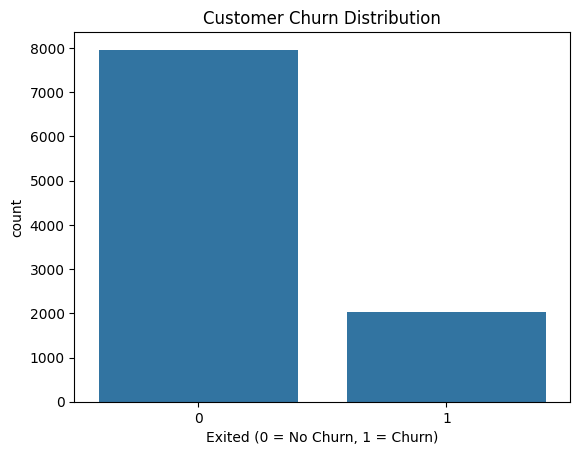


Confusion Matrix:
[[1531   62]
 [ 235  172]]


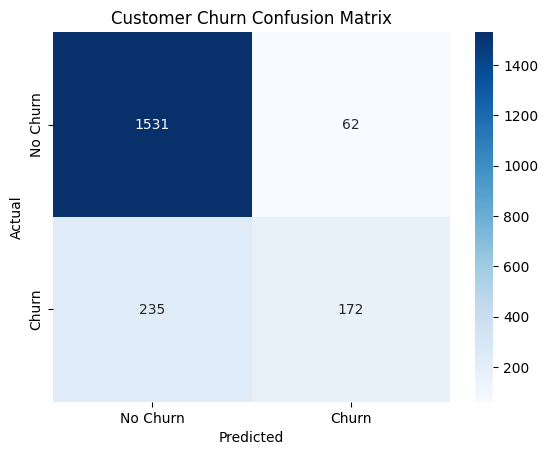

Precision: 0.7350427350427351
Recall: 0.4226044226044226
F1 Score: 0.5366614664586583

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.96      0.91      1593
       Churn       0.74      0.42      0.54       407

    accuracy                           0.85      2000
   macro avg       0.80      0.69      0.72      2000
weighted avg       0.84      0.85      0.84      2000


Sample Prediction:
No Churn


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, classification_report

df = pd.read_csv("Churn_Modelling (1).csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Exited"].value_counts())

sns.countplot(data=df, x="Exited")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = No Churn, 1 = Churn)")
plt.show()

df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True, dtype=int)

X = df.drop("Exited", axis=1)
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"],
            yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn Confusion Matrix")
plt.show()

print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("\nSample Prediction:")
print("Churn" if model.predict(X_test.iloc[[0]])[0] == 1 else "No Churn")
